# Variable and Memory Address

A **variable** is a name that refers to an object in memory.

When we create a variable, Python creates an object and the variable **refers to that object**.

```python
a = 10

print(a)
print(id(a))
```
### Output:

10
140732123456

The number returned by `id()` is the unique identity of the object during its lifetime.

### Important:

**A variable is a name/reference, not the object itself.**

Variable ──────► Object in memory
   a                 10

# Aliasing
Two variables can refer to the same object.
```python
a = 10
b = a

print(a)
print(b)

print(id(a))
print(id(b))
```
Both `id(a)` and `id(b)` will be the same because both variables refer to the same object.
```python
print(a is b)
```
### Output:

True

### Important
**If we delete `a`, `b` will still point to `10`**.

Initially, `a` refers to the object `10`.

a ──────► 10

When we write `b = a`, `b` also refers to the same object.

a ──────► 10 ◄────── b

Both `a` and `b` refer to the same object.

Now, if we delete a:
```python
del a
```
The reference from `a` is removed.

a            10 ◄────── b
        ↑
   object still exists

The object `10` is not deleted, because `b` is still referring to it.

# Variable References and Reassignment

Consider the following code:

```python
a = 10
b = a
a = 6
```

After:

`a = 10`

`a` refers to the object `10`.

a ──────► 10

After:

`b = a`

`b` also refers to the same object `10`.

a ──────► 10 ◄────── b

Now we execute:

`a = 6`

`a` is made to refer to a new object `6`.

`b` is still referring to the original object `10`.

a ──────► 6

b ──────► 10

So:
```python
print(a)
print(b)
```
### Output:

6
10

### Important Point

When we write:

`a = 6`

we are not changing the object `10`.

We are simply changing what the variable `a` refers to.

Before:

a ──────► 10 ◄────── b


After `a = 6`:

a ──────► 6

b ──────► 10

**This is because `int` objects are immutable.**

# Checking Reference Count

We can check the reference count of an object using `sys.getrefcount()`.

```python
import sys

a = [1, 2, 3]

print(sys.getrefcount(a))

b = a

print(sys.getrefcount(a))

del b

print(sys.getrefcount(a))
```
### Output:

2
3
2

**The output is usually one more than the actual reference count because `getrefcount()` temporarily creates an additional reference to the object.**

### Understanding the Example

After:
```python
a = [1, 2, 3]
```
a ──────► [1, 2, 3]

`a` is one reference, and `getrefcount()` temporarily adds another.

So the output is:

2

After:
```python
b = a
```
Both `a` and `b` refer to the same object.

a ──────► [1, 2, 3] ◄────── b

The output becomes:

3

Again, `2` actual references + `1` temporary reference from `getrefcount()`.

After:
```python
del b
```
Only `a` refers to the object.

a ──────► [1, 2, 3]

So the output becomes:

2

### Remember: 
`sys.getrefcount()` adds a temporary reference, so subtract `1` from the displayed value to estimate the actual reference count.

# Garbage Collector

The **Garbage Collector (GC)** is a part of Python's memory management system.

It automatically finds objects that are **no longer needed** and removes them from memory.

```python
a = [1, 2, 3]
b = a
```
Both `a` and `b` refer to the same object.

a ──────► [1, 2, 3] ◄────── b
              ↑
         2 references

Now:

del a

Only `b` refers to the object.

         [1, 2, 3] ◄────── b
              ↑
         1 reference

Now:

del b

There are no references left.

         [1, 2, 3]
              ↑
        0 references

The object becomes eligible for garbage collection.

### Circular References

Garbage collection is especially useful for handling circular references.

For example:
```python
a = []
b = []

a.append(b)
b.append(a)
```
#### Step 1
a = []
b = []

We have two separate empty lists:

a ──────► []
         
b ──────► []

#### Step 2
a.append(b)

We add the list `b` itself inside `a`.

So now:

a ──────► [ b ]
             │
             ▼
            []

In other words:
```python
print(a)
```
gives:

[[]]

But `a` contains a reference to the actual `b` list, not a copy of it.

#### Step 3

Now we execute:
```python
b.append(a)
```
We add the list `a` itself inside b.

Now:

a ──────► [ b ]
             │
             ▼
b ──────► [ a ]
             │
             └──────────► a

More clearly:

        ┌─────────────┐
        │             ▼
a ───► [ b ]        [ a ] ◄─── b
        ▲             │
        │             │
        └─────────────┘

So:

`a` contains `b`
`b` contains `a`

That's why they are circularly referencing each other.

What happens when we delete them?
```python
del a
del b
```
The variables `a` and `b` are gone, but the two list objects still have references to each other:

      ┌──────────► [ List B ]
      │                 │
      │                 ▼
[ List A ] ◄────────────┘

There is no variable pointing to either list anymore, so the objects are unreachable from the program, but they still reference each other.

This is the type of situation that Python's Garbage Collector can detect and clean up.

Even if we delete both variables:
```python
del a
del b
```
the objects can still refer to each other.

The Garbage Collector can detect such unreachable objects and clean them up.

# Object Identity

### Example 1: Small Integers

```python
a = 4
b = 4

print(id(a))
print(id(b))
print(a is b)
```
Output
Same id
Same id
True

#### Explanation

**Python may reuse/cache small integer objects.**

So, in this case:

a ──────► 4 ◄────── b

Both `a` and `b` can refer to the same integer object.

Therefore:

`id(a)` and `id(b)` are the same.

`a is b` is `True`.

is checks whether two variables refer to the same object.

**The exact small-integer caching behavior is an implementation detail, but CPython commonly caches integers such as -5 to 256.**

**-5 to 256 is a common CPython optimization, not a rule of Python itself.**

#### Example 2: Lists
```python
a = [1, 2]
b = [1, 2]

print(id(a))
print(id(b))
print(a is b)
```
### Output
Different id
Different id
False

#### Explanation

Although both lists contain the same values, Python creates two separate list objects.

a ──────► [1, 2]

b ──────► [1, 2]

Therefore:

`id(a)` and `id(b)` are different.

`a is b` is `False`.

**The lists have the same value/content, but they are different objects.**

In [6]:
a = 4
b = 4
print(id(a))
print(id(b))
print(a is b)

140730275922952
140730275922952
True


In [7]:
a = [1, 2]
b = [1, 2]
print(id(a))
print(id(b))
print(a is b)

2236522528256
2236503702976
False


**Python uses same object refrence for strings having valid identifiers**
#### Rules for identifiers
- Can contain letters (a-z, A-Z)
- Can contain digits (0-9), but cannot start with a digit
- Can contain underscore (_)
- Cannot contain spaces
- Cannot contain special characters such as @, #, -, $
- Cannot be a Python keyword
```python
a = "Nitish"
b = "Nitish"
print(id(a))
print(id(b))
```
### Output
2236522951568
2236522951568

```python
a = "Nitish Kumar"
b = "Nitish Kumar"
print(id(a))
print(id(b))
```
### Output
2236522874416
2236522889136

**Different id because `space` is not a valid identifier**.
```python
a = "Nitish_Kumar"
b = "Nitish_Kumar"
print(id(a))
print(id(b))
```
### Output
2236522876528
2236522876528

In [8]:
a = "Nitish"
b = "Nitish"
print(id(a))
print(id(b))

2236522951568
2236522951568


In [9]:
a = "Nitish Kumar"
b = "Nitish Kumar"
print(id(a))
print(id(b))

2236522874416
2236522889136


In [10]:
a = "Nitish_Kumar"
b = "Nitish_Kumar"
print(id(a))
print(id(b))

2236522876528
2236522876528


### Lists in Memory

#### Example
```python
a = [10, 20, 30]
```
Conceptually, memory looks like:

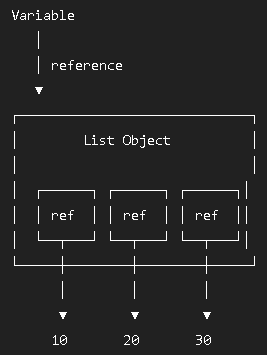

So the list doesn't conceptually store the actual integers inside itself. It stores references to the objects.

#### Step 1: Creating the list
```python
a = [10, 20, 30]
```
There is a list object somewhere in memory:

a ───────► [ reference | reference | reference ]

And those references point to the integer objects:

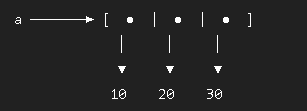

#### Step 2: Two variables pointing to the same list
```python
a = [10, 20, 30]
b = a
```
Now:

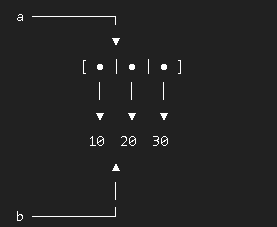

There is only one list object.

Both `a` and `b` point to that same list.

Therefore:
```python
print(a is b)
```
True

#### One important point

For:
```python
a = [10, 20, 30]
```
Think of it as:

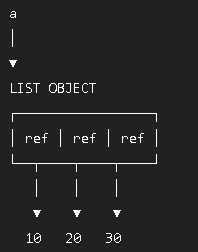

List = container of references to objects.

**This becomes especially important when you learn nested lists, shallow copy, deep copy, and mutable objects.**

### Important
```python
a = [10, 20, 30]
a[2] = 10

print(id(a[0]))
print(id(a[2]))
print(a[0] is a[2])
```

### Typically:

Same id

Same id

True

### Conceptually:

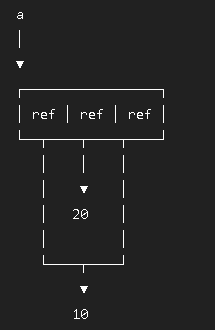



# Mutable and Immutable Objects

## Immutable

**Immutable means an object cannot be changed after it is created.**

If you try to change an immutable object, Python creates a **new object** instead of modifying the existing object.

### Examples of Immutable Types

- `int`
- `float`
- `bool`
- `str`
- `tuple`
- `frozenset`

### Example: Integer

```python
a = 10

a = 20
```
It may look like `10` was changed to `20`, but that is not what happened.

### Conceptually:

Before:

a ─────► 10


After:

a ─────► 20

The integer object `10` was not modified.

`a` was simply made to refer to another integer object.

# Mutable

### Definition

**Mutable means an object can be changed after it is created.**

When a mutable object is modified, the **same object** is changed. A new object does not have to be created.

### Examples of Mutable Types

- `list`
- `dict`
- `set`

### Example: List

```python
a = [10, 20, 30]

a[0] = 100

print(a)
```
### Output:

[100, 20, 30]

The existing list was changed:

Before:

a ─────► [10, 20, 30]


After:

a ─────► [100, 20, 30]

The list object is still the same object.